In [1]:
%load_ext autoreload
%autoreload 2

import os, sys
dir1 = os.path.dirname(os.path.abspath('..'))
if not dir1 in sys.path: sys.path.append(dir1)

In [2]:
from pathlib import Path
import pickle
import yaml
import pandas as pd
import numpy as np
import scipy.signal as ss

import seaborn as sns
from utils.plots import *
from utils.figures import plot_metrics
from matplotlib.gridspec import GridSpec

from utils import models

FIG = 'fig3'
config_fpath = Path(f'{FIG}.yml')
df_fpath = Path(f'{FIG}_df.csv')

In [3]:
data_dir = Path('../../experiments/simulation_base')
idx = '0001'

obs_fpath = data_dir / 'idx' / idx / f'{idx}_sig_obs.csv'
df_obs = pd.read_csv(obs_fpath)
t, y_obs = df_obs.t.values, df_obs.y.values

filt_fpath = data_dir / 'idx' / idx / 'filt' / f'{idx}_F_pyp.csv'
df_filt = pd.read_csv(filt_fpath)
t_filt, y_filt = df_filt.t.values, df_filt.y.values

y_filt = y_filt.copy()
y_filt -= y_filt.mean()
y_filt *= y_obs.std() / y_filt.std()
y_filt += y_obs.mean()


time_fpath = data_dir / 'idx' / idx / 'time' / f'{idx}_F_pyp_T_pyp.sp.csv'
df_time = pd.read_csv(time_fpath)

bpd_fpath = data_dir / 'idx' / idx / 'filt' / f'{idx}_F_bpd.csv'
df_bpd = pd.read_csv(bpd_fpath)
t_bpd, y_bpd = df_bpd.t.values, df_bpd.y.values

sol_fpath = data_dir / 'idx' / idx / f'{idx}_soln_bpd.pkl'
with open(sol_fpath, 'rb') as f:
    bpd = pickle.load(f)

assert np.all(np.isclose(t, t_filt))
assert np.all(np.isclose(t, t_bpd))
fs = (t.size-1)/(t.max() - t.min())

true_fpath = data_dir / 'idx' / idx / f'{idx}_soln_true.pkl'
with open(true_fpath, 'rb') as f:
    true = pickle.load(f)
y_true = models.evaluate(t, true['z'], true['w'], true['f_h'], true['g'])[0]

3.0 3.265625


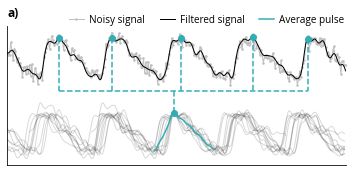

In [4]:
def subfigure_a(sub='a)'):
    ta, tb = 3.0, 7.5
    win = (t >= ta) & (t <= tb)
    ta, tb = t[win].min(), t[win].max()

    offset = (y_filt[win].max()-y_filt[win].min()) *1.75
    y_filt2 = y_filt + offset
    plt.plot(t[win], y_obs[win]+offset, '.-', c=cp[-1], markersize=3, zorder=-2, label='Noisy signal')
    plt.plot(t[win], y_filt2[win], c='k', lw=1, label='Filtered signal')
    zu = [z for z in df_time.z.values if ta<z<tb]
    yu = np.interp(zu, t, y_filt2)
    plt.scatter(zu, yu, c=cp[3], zorder=99)

    y = y_filt.copy()

    # trim only z within observed time window
    z = df_time.z.values
    z = z[(z > min(t)) & (z < max(t))]

    fs = (len(t)-1)/(t.max()-t.min())

    N, M = len(y), len(z)
    idx = np.argmax(t >= z[:,None], axis=1)+1
    y_shift = np.full((M,N), np.nan)
    for j in range(M):
        k = N//2 - idx[j]
        y_shift[j,max(0,k):min(N,N+k)] = y[max(0,-k):min(N,N-k)]
    h_mean = np.nanmean(y_shift, axis=0)

    # get median R-R interval
    med_rri = np.median(np.diff(np.sort(z)))
    if np.isnan(med_rri):
        return np.array([[np.nan]]), np.array([0.0])
    W = int(np.floor(med_rri*fs))

    ia, ib = N//2-W//2, N//2+W//2
    loc_peak = ia + np.argmax(h_mean[ia:ib])

    ia, ib = loc_peak-W, loc_peak
    loc_start = ia + np.argmin(h_mean[ia:ib])

    ia, ib = loc_peak, loc_peak+W
    loc_end = ia + np.argmin(h_mean[ia:ib])

    ta2, tb2 = t.mean() - 2.24, t.mean() + 2.26
    win2 = (t >= ta2) & (t <= tb2)
    ta2, tb2 = t[win2].min(), t[win2].max()

    tt = t + ta-ta2
    print(ta, ta2)

    lines = plt.plot(tt[win2], y_shift.T[win2], c='k', alpha=0.15)
    plt.plot(tt[loc_start:loc_end], h_mean[loc_start:loc_end], lw=1.5, c=cp[3], label='Average pulse')
    plt.scatter(tt[loc_peak], h_mean[loc_peak], c=cp[3], zorder=99)

    z2, y2 = tt[loc_peak], h_mean[loc_peak]
    ymid = np.mean([np.min(y_filt2[win]), np.nanmax(y_shift.T[win2])])
    for z1, y1 in zip(zu, yu):
        plt.plot([z1, z1], [y1, ymid], c=cp[3], lw=1.5, ls='--')
    plt.plot([min(zu), max(zu)], [ymid, ymid], c=cp[3], lw=1.5, ls='--')
    plt.plot([z2, z2], [ymid, y2], c=cp[3], lw=1.5, ls='--')
        
    plt.gca().set_ymargin(0.05)
    plt.yticks([])
    plt.xticks([])

    plt.legend(loc='lower right', bbox_to_anchor=(1, 1),
               ncol=3, columnspacing=1.5,
               frameon=False, borderpad=0.0, borderaxespad=0.1,
               handlelength=1.5, handletextpad=0.5)
    plt.title(sub, loc='left', pad=10, fontdict={'fontweight': 'bold'})
    
plt.figure(figsize=(5,2.5))
subfigure_a()
plt.show()


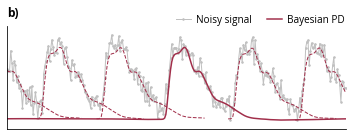

In [5]:
from utils import models

def subfigure_b(sub='b)'):
    ta, tb = 3.0, 7.5
    win = (t >= ta) & (t <= tb)
    ta, tb = t[win].min(), t[win].max()

    _, y_bpd = models.evaluate(
        t = t,
        z = bpd['z'],
        w = bpd['w'],
        f_h = bpd['f_h'],
        a = bpd.get('a'),
        b = bpd.get('b'),
        f_b = bpd.get('f_b'),
        g = bpd.get('g'),
    )

    plt.plot(t[win], y_obs[win], '.-', c=cp[-1], markersize=3, zorder=-2, label='Noisy signal')
    
    for zi in true['z']:
        if ta-1.0 < zi < tb:

            _, h_i = models.evaluate(
                t = t,
                z = [zi,],
                w = bpd['w'],
                f_h = bpd['f_h'],
                a = bpd.get('a'),
                b = bpd.get('b'),
                f_b = bpd.get('f_b'),
                g = bpd.get('g'),
            )
            h_i = np.array(h_i)

            if 5.0 < zi < 5.5:
                lw, ls = 1.5, '-'
                label = 'Bayesian PD'
            else:
                h_i[(t<zi-0.05)|(t>zi+1.4)] = np.nan
                lw, ls = 1, '--'
                label = None
            plt.plot(t[win], h_i[win], c=cp[1], lw=lw, ls=ls, label=label)
            tdot, hdot = t[np.argmax(~np.isnan(h_i))], h_i[np.argmax(~np.isnan(h_i))]

    plt.gca().set_ymargin(0.1)
    plt.xticks([])
    plt.gca().tick_params(axis="x", direction="in", pad=-10)
    plt.yticks([])

    plt.legend(loc='lower right', bbox_to_anchor=(1, 1),
               ncol=3, columnspacing=1.5,
               frameon=False, borderpad=0.0, borderaxespad=0.1,
               handlelength=1.5, handletextpad=0.5)
    plt.title(sub, loc='left', pad=10, fontdict={'fontweight': 'bold'})

plt.figure(figsize=(5,2))
subfigure_b()
plt.show()


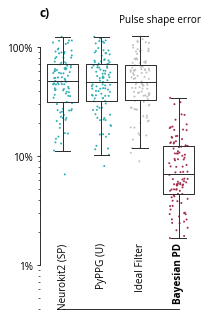

median metrics: (%)


method
F_ideal__T_ideal__S_avg        47.924100
F_nk__F_nk_T_nk__S_avg         48.653473
F_pyp__F_pyp_T_pyp.u__S_avg    47.746357
S_bpd                           6.920859
Name: h_errea, dtype: float64

In [6]:
with open(config_fpath, 'r') as f:
    config = yaml.safe_load(f)
df = pd.read_csv(df_fpath)

y = config['y'][0]
metric = y['metric']

def subfigure_c_log(sub='c)', debug = False):
    title = y['name']
    methods = [x['method'] for x in y['x']]
    names = [x['name'] for x in y['x']]
    df_temp = plot_metrics(df, metric, methods, names, log=True)
    
    plt.gca().set_xmargin(0.05)
    
    plt.gca().tick_params(axis="x", direction="in", pad=-66)
    if not debug:
        plt.minorticks_off()
    plt.yticks([0.01, 0.1, 1], ['1%', '10%', '100%'])
    plt.ylim(0.004, None)
    sns.despine(ax=plt.gca(), bottom=(not debug), trim=True)
    labels = plt.gca().get_xticklabels()
    labels[-1].set_weight('bold')

    plt.plot([np.nan], [np.nan], lw=0, label=title)
    plt.legend(loc='lower right', bbox_to_anchor=(1, 1),
               ncol=3, columnspacing=1.5,
               frameon=False, borderpad=0.0, borderaxespad=0.1,
               handlelength=1.5, handletextpad=0.5)
    plt.title(sub, loc='left', pad=10, fontdict={'fontweight': 'bold'})

    return df_temp

plt.figure(figsize=(3,4.5))
df_temp = subfigure_c_log(debug=True)
plt.show()

print('median metrics: (%)')
df_temp.groupby('method')[metric].median() * 100


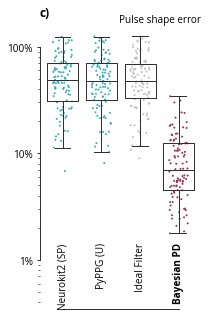

median metrics: (%)


method
F_ideal__T_ideal__S_avg        47.924100
F_nk__F_nk_T_nk__S_avg         48.653473
F_pyp__F_pyp_T_pyp.u__S_avg    47.746357
S_bpd                           6.920859
Name: h_errea, dtype: float64

In [7]:
with open(config_fpath, 'r') as f:
    config = yaml.safe_load(f)
df = pd.read_csv(df_fpath)

y = config['y'][0]
metric = y['metric']

def subfigure_c(sub='c)', debug = False):
    title = y['name']
    methods = [x['method'] for x in y['x']]
    names = [x['name'] for x in y['x']]
    df_temp = plot_metrics(df, metric, methods, names, log=True)
    
    plt.gca().set_xmargin(0.05)
    
    plt.gca().tick_params(axis="x", direction="in", pad=-66)
    if not debug:
        plt.minorticks_off()
    plt.yticks([0.01, 0.1, 1], ['1%', '10%', '100%'])
    plt.ylim(0.0035, None)
    sns.despine(ax=plt.gca(), bottom=(not debug), trim=True)
    labels = plt.gca().get_xticklabels()
    labels[-1].set_weight('bold')

    plt.plot([np.nan], [np.nan], lw=0, label=title)
    plt.legend(loc='lower right', bbox_to_anchor=(1, 1),
               ncol=3, columnspacing=1.5,
               frameon=False, borderpad=0.0, borderaxespad=0.1,
               handlelength=1.5, handletextpad=0.5)
    plt.title(sub, loc='left', pad=10, fontdict={'fontweight': 'bold'})

    return df_temp

plt.figure(figsize=(3,4.5))
df_temp = subfigure_c(debug=True)
plt.show()

print('median metrics: (%)')
df_temp.groupby('method')[metric].median() * 100


3.0 3.265625


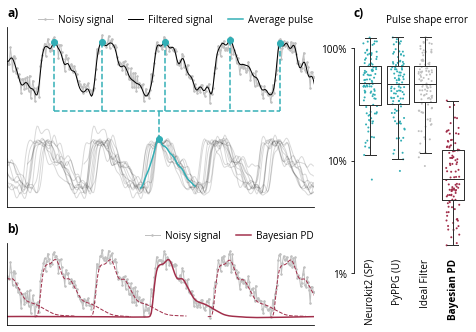

In [8]:
fig = plt.figure(figsize=(6.5,4.5), layout="constrained")

titlefont = {'fontweight':'bold'}
gs = GridSpec(2, 2, figure=fig,
              width_ratios=[8,3], height_ratios=[2.2, 1],
              wspace=0.03, hspace=0.05)
fig.add_subplot(gs[0, 0])
plt.title('a)', loc='left', pad=20, fontdict=titlefont)
subfigure_a()
fig.add_subplot(gs[1, 0])
plt.title('b)', loc='left', pad=20, fontdict=titlefont)
subfigure_b()
fig.add_subplot(gs[:, 1])
subfigure_c()

plt.savefig(f'{FIG}.pdf', transparent=True)
plt.savefig(f'{FIG}.png', transparent=True, dpi=200)
plt.show()
